In [1]:
import numpy as np
import tensorflow as tf

print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

NumPy: 1.26.4
TensorFlow: 2.16.1
GPUs: []


In [2]:
import numpy as np 
import matplotlib.pyplot as plt
import tensorflow as tf
import deepxde as dde

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


In [3]:
rho = 1
mu = 1
u_in = 1
D = 1
L = 2

In [6]:
geom = dde.geometry.Rectangle(xmin = [-L/2,-D/2], xmax=[+L/2,+D/2])


In [9]:
def boundary_wall(X, on_boundary):
    print("X",X)
    print("on_boundary", on_boundary)
    
    on_wall = np.logical_and(np.logical_or(np.isclose(X[1], -D/2, rtol=1e-05, atol=1e-08),
                                           np.isclose(X[1], +D/2, rtol=1e-05, atol=1e-08)), on_boundary)
    return on_wall

def boundary_inlet(X, on_boundary):
    on_inlet = np.logical_and(np.isclose(X[0], -L/2, rtol=1e-05, atol=1e-08), on_boundary)
    return on_inlet

def boundary_outlet(X, on_boundary):
    on_inlet = np.logical_and(np.isclose(X[0], +L/2, rtol=1e-05, atol=1e-08), on_boundary)
    return on_inlet

In [ ]:
bc_wall_u = dde.DirichletBC(geom, lambda X:0., boundary_wall, component=0)
bc_wall_v = dde.DirichletBC(geom, lambda X:0., boundary_wall, component=1)

bc_inlet_u = dde.DirichletBC(geom, lambda X:u_in, boundary_inlet, component=0)
bc_inlet_v = dde.DirichletBC(geom, lambda X:0., boundary_inlet, component=1)

bc_outlet_p = dde.DirichletBC(geom, lambda X:0., boundary_outlet, component=2) # 2 is for pressure
bc_outlet_v = dde.DirichletBC(geom, lambda X:0., boundary_outlet, component=1)

In [11]:
def pde(X,Y):
    du_x = dde.grad.jacobian(Y, X, i=0, j=0)
    du_y = dde.grad.jacobian(Y, X, i=0, j=1)
    
    dv_x = dde.grad.jacobian(Y, X, i=1, j=0)
    dv_y = dde.grad.jacobian(Y, X, i=1, j=1)
    
    dp_x = dde.grad.jacobian(Y, X, i=2, j=0)
    dp_y = dde.grad.jacobian(Y, X, i=2, j=1)

    du_xx = dde.grad.hessian(Y, X, component=0, i=0, j=0)
    du_yy = dde.grad.hessian(Y, X, component=0, i=1, j=1)
    dv_xx = dde.grad.hessian(Y, X, component=1, i=0, j=0)
    dv_yy = dde.grad.hessian(Y, X, component=1, i=1, j=1)

    pde_u = Y[:,0:1] * du_x + Y[:,1:2] * du_y + 1/rho * dp_x - (mu/rho) * (du_xx + du_yy)
    pde_v = Y[:,0:1] * dv_x + Y[:,1:2] * dv_y + 1/rho * dp_y - (mu/rho) * (dv_xx + dv_yy)
    pde_cont = du_x + dv_y

    return [pde_u, pde_v, pde_cont]


In [15]:
data = dde.data.PDE(geom, 
                    pde,
                    [bc_wall_u,
                     bc_wall_v,
                     bc_inlet_u,
                     bc_inlet_v,
                     bc_outlet_p,
                     bc_outlet_v],
                    num_domain=2000,
                    num_boundary=200,
                    num_test=200)

X [1.  0.5]
on_boundary True
X [ 0.5 -0.5]
on_boundary True
X [-0.5  0.5]
on_boundary True
X [-0.25 -0.5 ]
on_boundary True
X [0.25 0.5 ]
on_boundary True
X [ 1.   -0.25]
on_boundary True
X [-1.    0.25]
on_boundary True
X [-0.625 -0.5  ]
on_boundary True
X [0.625 0.5  ]
on_boundary True
X [ 0.875 -0.5  ]
on_boundary True
X [-0.875  0.5  ]
on_boundary True
X [ 0.125 -0.5  ]
on_boundary True
X [-0.125  0.5  ]
on_boundary True
X [1.    0.125]
on_boundary True
X [-1.    -0.125]
on_boundary True
X [-0.8125 -0.5   ]
on_boundary True
X [0.8125 0.5   ]
on_boundary True
X [ 0.6875 -0.5   ]
on_boundary True
X [-0.6875  0.5   ]
on_boundary True
X [-0.0625 -0.5   ]
on_boundary True
X [0.0625 0.5   ]
on_boundary True
X [ 1.     -0.0625]
on_boundary True
X [-1.      0.0625]
on_boundary True
X [-0.4375 -0.5   ]
on_boundary True
X [0.4375 0.5   ]
on_boundary True
X [ 1.     -0.4375]
on_boundary True
X [-1.      0.4375]
on_boundary True
X [ 0.3125 -0.5   ]
on_boundary True
X [-0.3125  0.5   ]
on_bound

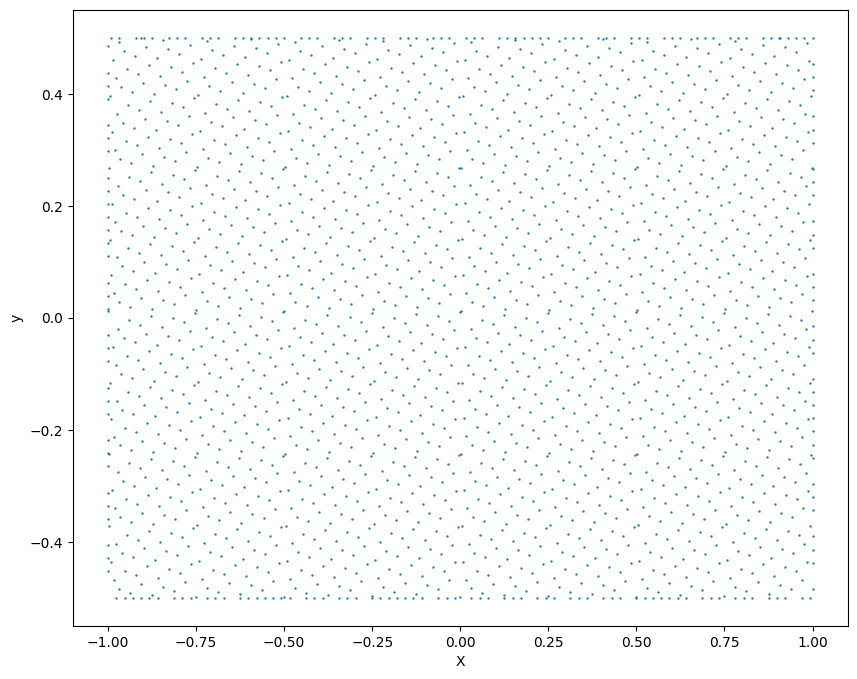

In [18]:
plt.figure(figsize=(10,8))
plt.scatter(data.train_x_all[:,0], data.train_x_all[:,1], s=0.5)
plt.xlabel("X")
plt.ylabel("y")
plt.show()


In [20]:
net = dde.maps.FNN([2] + [64]*5 + [3] , "tanh", "Glorot uniform")

In [22]:
model = dde.Model(data, net)
model.compile("adam", lr=1e-3)

Compiling model...
'compile' took 2.348312 s



In [23]:
losshistory, train_state = model.train(epochs=10000)

Training model...

Step      Train loss                                                                                    Test loss                                                                                     Test metric
0         [9.63e-02, 1.73e-03, 1.84e-02, 2.05e-02, 1.59e-03, 1.28e+00, 5.07e-03, 8.76e-02, 5.06e-03]    [9.74e-02, 1.75e-03, 1.90e-02, 2.05e-02, 1.59e-03, 1.28e+00, 5.07e-03, 8.76e-02, 5.06e-03]    []  
1000      [5.68e-03, 8.89e-03, 7.99e-03, 2.41e-02, 1.77e-02, 3.58e-02, 1.15e-03, 8.79e-04, 5.20e-04]    [4.57e-03, 9.52e-03, 5.21e-03, 2.41e-02, 1.77e-02, 3.58e-02, 1.15e-03, 8.79e-04, 5.20e-04]    []  
2000      [1.94e-03, 6.96e-04, 4.76e-03, 2.00e-02, 1.31e-02, 2.61e-02, 1.43e-03, 6.80e-04, 5.88e-05]    [1.71e-03, 4.60e-04, 2.65e-03, 2.00e-02, 1.31e-02, 2.61e-02, 1.43e-03, 6.80e-04, 5.88e-05]    []  
3000      [1.63e-03, 8.54e-04, 3.26e-03, 1.76e-02, 1.09e-02, 2.20e-02, 2.61e-03, 4.01e-05, 8.91e-06]    [1.08e-03, 6.01e-04, 1.56e-03, 1.76e-02, 1.09e-02, 2.20e-0

Compiling model...
'compile' took 0.001069 s

Training model...

Step      Train loss                                                                                    Test loss                                                                                     Test metric
10000     [2.28e-03, 7.60e-04, 2.36e-03, 1.43e-02, 6.30e-03, 1.40e-02, 5.47e-03, 7.13e-06, 7.76e-06]    [1.55e-03, 2.95e-04, 9.88e-04, 1.43e-02, 6.30e-03, 1.40e-02, 5.47e-03, 7.13e-06, 7.76e-06]    []  
11000     [9.24e-04, 4.71e-04, 9.47e-04, 6.85e-03, 1.10e-03, 4.96e-03, 1.68e-03, 1.11e-05, 4.12e-06]    [5.19e-04, 3.02e-04, 4.95e-04, 6.85e-03, 1.10e-03, 4.96e-03, 1.68e-03, 1.11e-05, 4.12e-06]    []  
12000     [4.62e-04, 3.44e-04, 5.03e-04, 4.47e-03, 8.46e-04, 3.76e-03, 1.13e-03, 2.22e-05, 4.12e-06]    [2.38e-04, 2.35e-04, 1.14e-04, 4.47e-03, 8.46e-04, 3.76e-03, 1.13e-03, 2.22e-05, 4.12e-06]    []  
13000     [3.92e-04, 3.70e-04, 4.05e-04, 3.18e-03, 9.03e-04, 2.87e-03, 7.73e-04, 2.94e-05, 2.00e-06]    [3.24e-04, 2

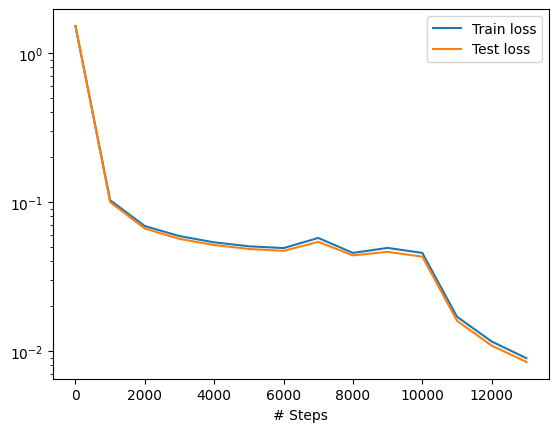

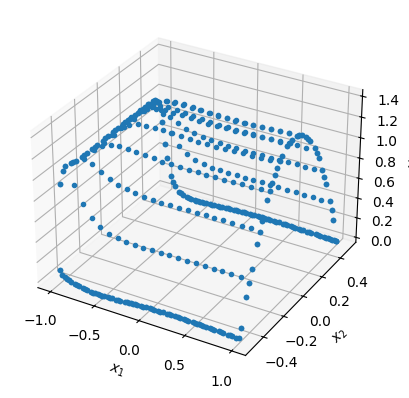

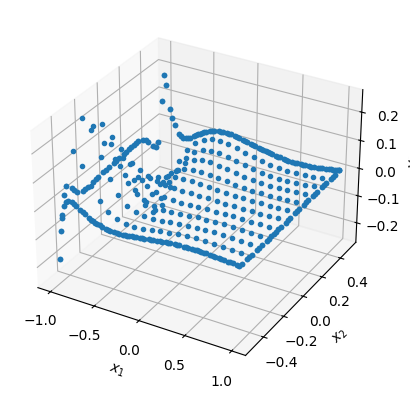

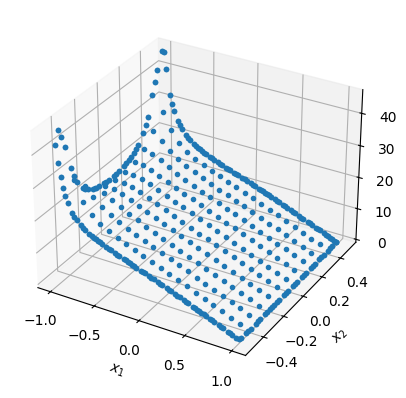

In [24]:
dde.optimizers.config.set_LBFGS_options(maxiter=3000)
model.compile("L-BFGS")
losshistory, train_state = model.train()
dde.saveplot(losshistory, train_state, issave=False, isplot=True)

In [25]:
samples = geom.random_points(500000)
result = model.predict(samples)

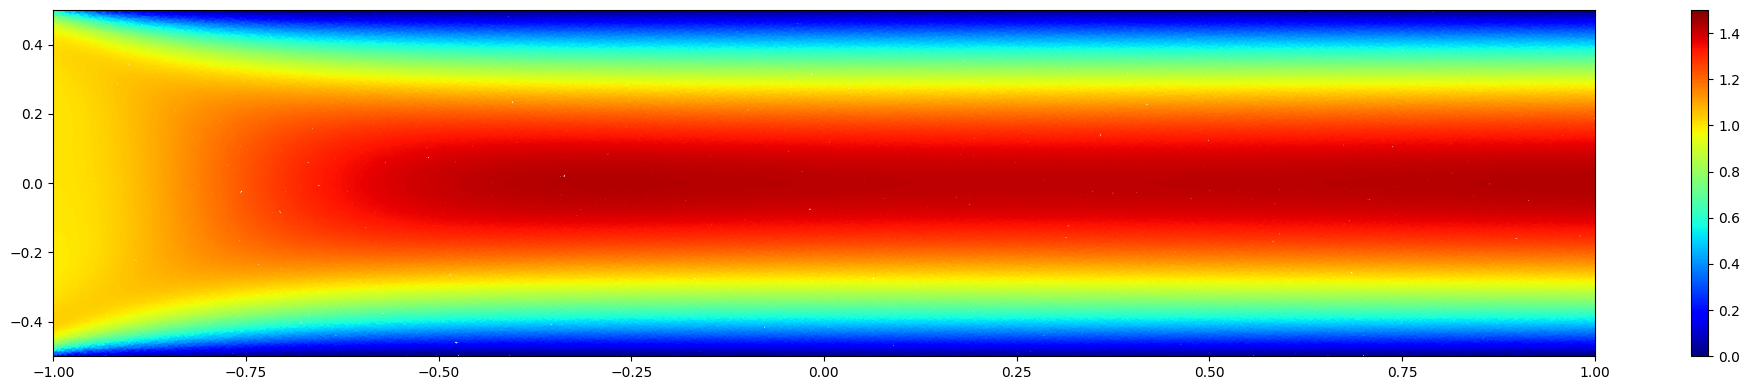

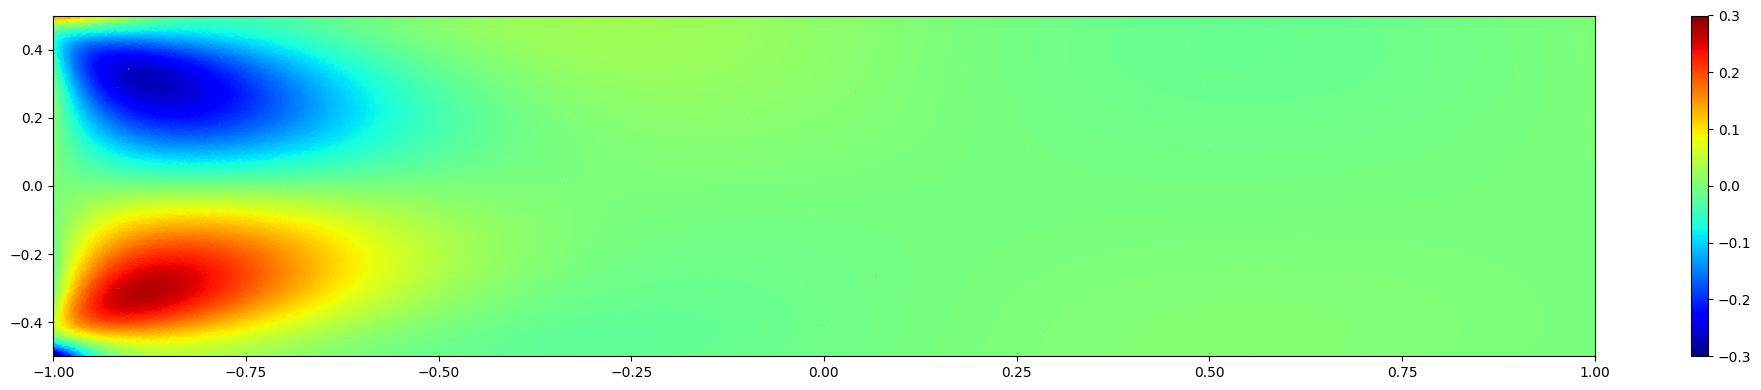

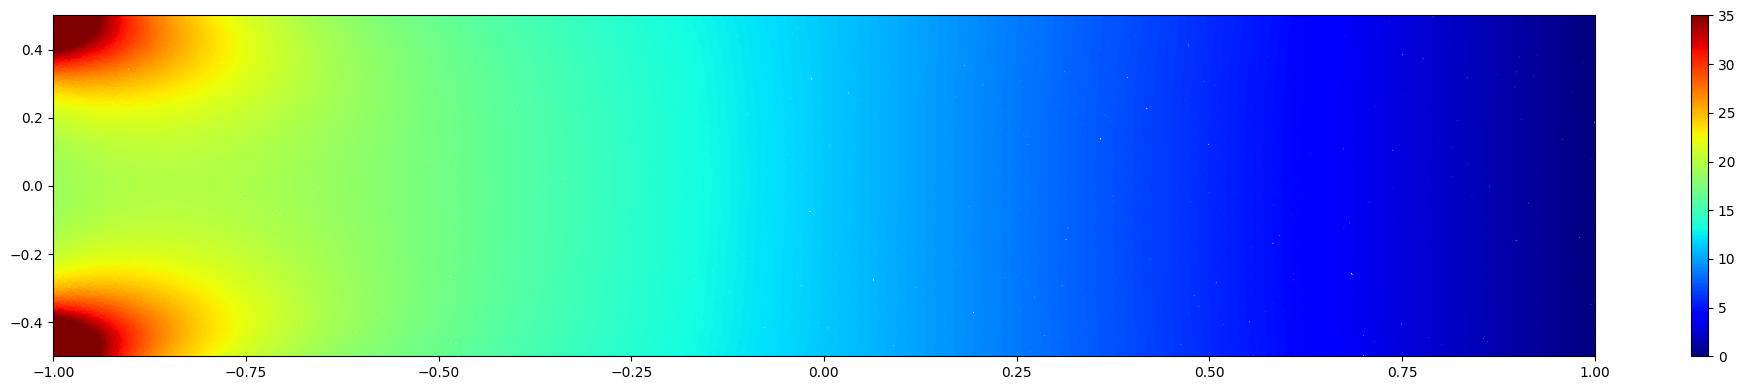

In [27]:
color_legend = [[0,1.5], [-0.3,0.3], [0,35]]

for idx in range(3):
    plt.figure(figsize=(20,4))
    plt.scatter(samples[:,0],
                samples[:,1],
                c = result[:,idx],
                cmap = "jet",
                s=2)
    plt.colorbar()
    plt.clim(color_legend[idx])
    plt.xlim((0-L/2, L-L/2))
    plt.ylim((0-D/2, D-D/2))
    plt.tight_layout()
    plt.show()